# 12. Product – Brand & Manufacturer theo Label

## Câu hỏi

- National/Private brand history có khác nhau giữa Positive và Negative không?
- Số brand đã mua có khác label không?
- Dominant brand và mức độ tập trung vào dominant brand có liên quan propensity không?
- Historical manufacturer nào phân biệt hai label rõ hơn?

Mọi lịch sử sản phẩm chỉ dùng `[cutoff-90, cutoff-1]`.

## Notebook này làm gì

So sánh brand và manufacturer history giữa Positive và Negative label.

### Nội dung đã thực hiện

- Build brand/manufacturer report leakage-safe trong 90 ngày trước cutoff.
- So sánh lịch sử National/Private Brand.
- Phân tích brand diversity, dominant brand và loyalty concentration.
- Xếp hạng historical manufacturer phân biệt hai label.


In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt

from propensity.eda.product_brand_manufacturer_label import (
    load_product_brand_manufacturer_report,
)
from propensity.eda.product_brand_manufacturer_plots import (
    ManufacturerPlotConfig,
    plot_brand_diversity_boxplots,
    plot_brand_history_distribution,
    plot_dominant_brand_distribution,
    plot_manufacturer_history_distribution,
)


## 1. Build leakage-safe brand và manufacturer report

In [2]:
project_root = Path.cwd().resolve()
if project_root.name in ("notebooks", "draft_notebooks"):
    project_root = project_root.parent

raw_dir = project_root / "data" / "raw" / "Dunnhumby"
label_path = project_root / "data" / "processed" / "purchase_propensity_t90_h7_step7" / "household_cutoff_labels.parquet"

report = load_product_brand_manufacturer_report(
    label_path,
    raw_dir / "transaction_data.csv",
    raw_dir / "product.csv",
    observation_days=90,
)
manufacturer_plot_config = ManufacturerPlotConfig(
    top_n=20,
    min_observations=300,
)


## 2. Historical brand

Mỗi brand category có hai cột: tỷ lệ Negative và Positive household-cutoff từng mua brand đó. Category được sort theo số Negative observations, lớn nhất ở trên cùng.

In [3]:
report.historical_brand_summary

,dimension,category,label,n_observations,n_households,label_observations,within_label_share,0,1,positive_minus_negative_pp,absolute_gap_pp,total_observations
0,brand,National,0,79776,2456,94821,0.841333,0.841333,0.988261,14.692874,14.692874,185938
1,brand,National,1,106162,2469,107423,0.988261,0.841333,0.988261,14.692874,14.692874,185938
2,brand,Private,0,75482,2451,94821,0.796047,0.796047,0.980023,18.397561,18.397561,180759
3,brand,Private,1,105277,2461,107423,0.980023,0.796047,0.980023,18.397561,18.397561,180759


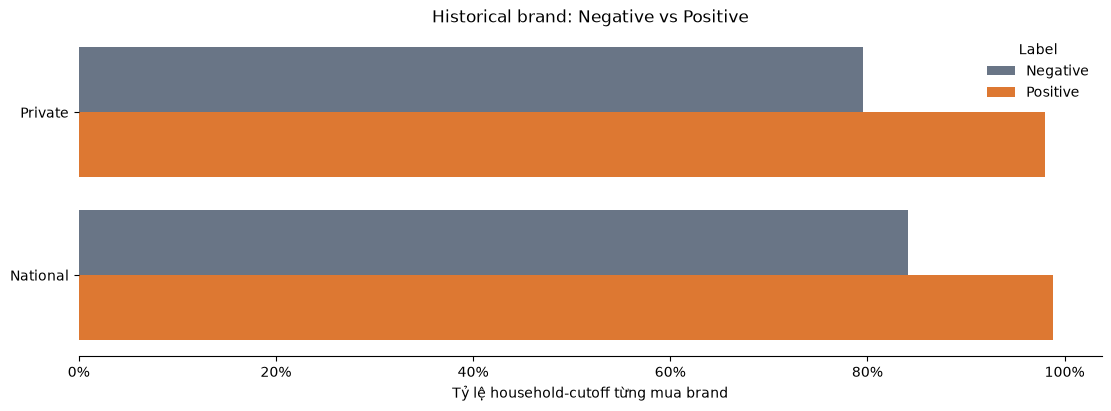

In [4]:
brand_history_figure = plot_brand_history_distribution(
    report.historical_brand_summary
)
plt.show()

## 3. Brand diversity và loyalty concentration

`dominant_brand_share_90d` là tỷ trọng product lines thuộc dominant brand. Giá trị gần 100% biểu thị lịch sử tập trung mạnh vào một brand.

In [5]:
report.numeric_summary_by_label

,feature,label,n_observations,missing_rate,q1,median,q3
0,n_brands_90d,0,94821,0.000000,2.000000,2.000000,2.000000
1,n_brands_90d,1,107423,0.000000,2.000000,2.000000,2.000000
2,dominant_brand_share_90d,0,80878,0.147045,0.639117,0.739469,0.833333
3,dominant_brand_share_90d,1,106384,0.009672,0.635323,0.721705,0.800000


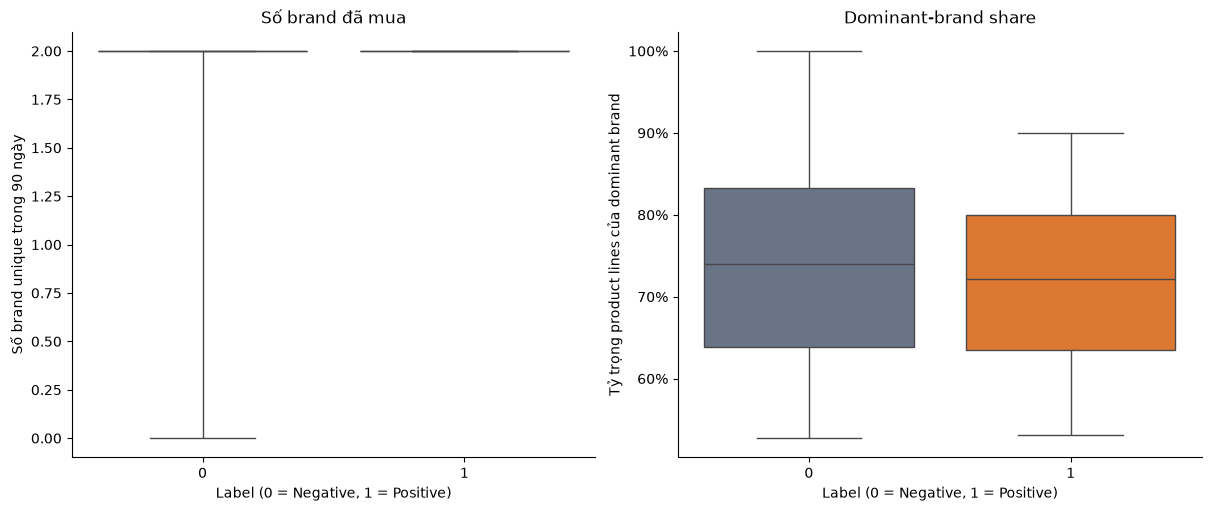

In [6]:
brand_diversity_figure = plot_brand_diversity_boxplots(report.feature_panel)
plt.show()

## 4. Dominant brand

Dominant brand là brand có nhiều product lines hợp lệ nhất trong window. Mỗi category có hai cột Negative/Positive và được sort theo số Negative observations.

In [7]:
report.dominant_brand_summary

,dimension,category,label,n_observations,n_households,label_observations,within_label_share,0,1,positive_minus_negative_pp,absolute_gap_pp,total_observations
0,dominant_brand,National,0,73950,2444,80878,0.91434,0.91434,0.938788,2.444767,2.444767,173822
1,dominant_brand,National,1,99872,2459,106384,0.938788,0.91434,0.938788,2.444767,2.444767,173822
2,dominant_brand,Private,0,6928,771,80878,0.08566,0.08566,0.061212,-2.444767,2.444767,13440
3,dominant_brand,Private,1,6512,787,106384,0.061212,0.08566,0.061212,-2.444767,2.444767,13440


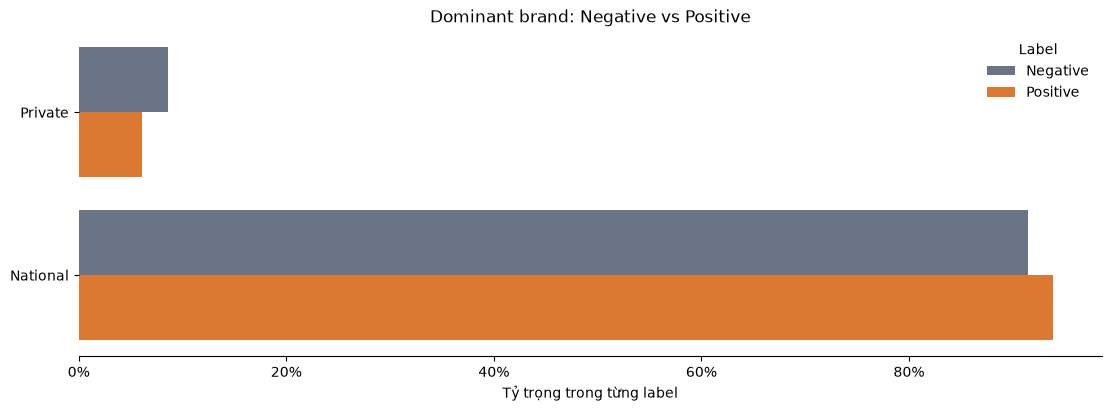

In [8]:
dominant_brand_figure = plot_dominant_brand_distribution(
    report.dominant_brand_summary
)
plt.show()

## 5. Historical manufacturer

Chỉ manufacturer có ít nhất 300 observations được xét. Biểu đồ giữ tối đa 20 manufacturer có chênh lệch distribution lớn nhất và sort theo số Negative observations.

In [9]:
report.manufacturer_summary.sort_values(
    "absolute_gap_pp",
    ascending=False,
)

,dimension,category,label,n_observations,n_households,label_observations,within_label_share,0,1,positive_minus_negative_pp,absolute_gap_pp,total_observations
4571,manufacturer,317,0,36749,2169,94821,0.387562,0.387562,0.691816,30.425464,30.425464,111066
4572,manufacturer,317,1,74317,2185,107423,0.691816,0.387562,0.691816,30.425464,30.425464,111066
11679,manufacturer,764,1,64784,2059,107423,0.603074,0.300007,0.603074,30.306645,30.306645,93231
11678,manufacturer,764,0,28447,2011,94821,0.300007,0.300007,0.603074,30.306645,30.306645,93231
9296,manufacturer,544,0,35124,2147,94821,0.370424,0.370424,0.669708,29.928333,29.928333,107066
...,...,...,...,...,...,...,...,...,...,...,...,...
3836,manufacturer,2813,0,7,1,94821,0.000074,0.000074,0.000074,0.000065,0.000065,15
8062,manufacturer,4849,0,8,2,94821,0.000084,0.000084,0.000084,-0.000059,0.000059,17
11446,manufacturer,655,0,8,1,94821,0.000084,0.000084,0.000084,-0.000059,0.000059,17
11447,manufacturer,655,1,9,1,107423,0.000084,0.000084,0.000084,-0.000059,0.000059,17


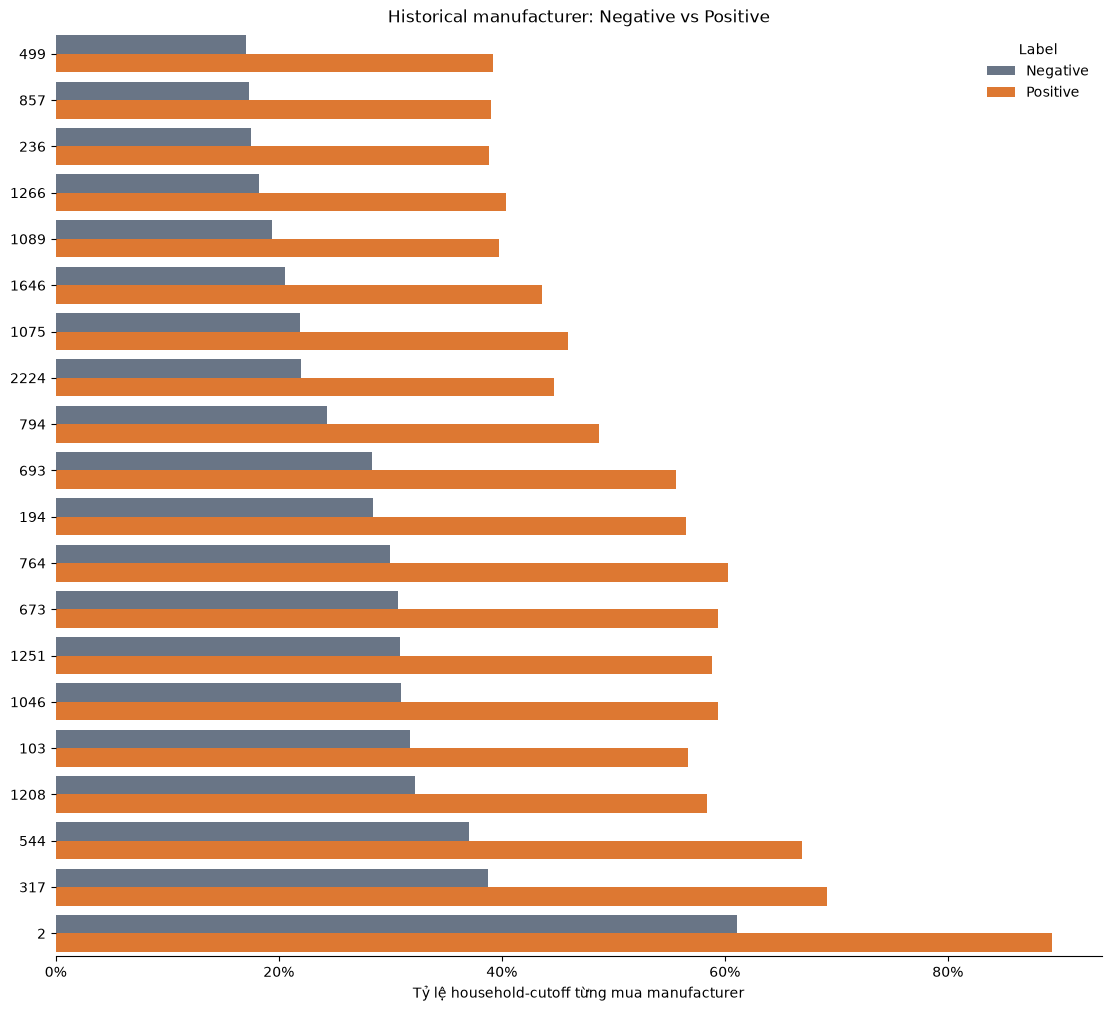

In [10]:
manufacturer_figure = plot_manufacturer_history_distribution(
    report.manufacturer_summary,
    manufacturer_plot_config,
)
plt.show()

## Lưu ý diễn giải

- Historical brand/manufacturer là multi-label: một household-cutoff có thể từng mua nhiều category.
- Manufacturer là identifier categorical, không phải đại lượng numeric.
- Category hiếm bị lọc để tránh tỷ lệ cực đoan do cỡ mẫu nhỏ.
- Household không có product mapping/activity có `n_brands_90d=0` và không tham gia dominant-brand chart.
- Giao dịch ngày cutoff không được dùng làm feature.
- Parquet label cần được tạo lại sau khi target window đổi thành `[cutoff, cutoff+6]`.